# Data Science Foundations: Session 2
## Topic: Data Science Lifecycle

**Student Name:** Atharv Chaudhari  
**Module:** Core Data Science & Applied Analytics  
**Key Focus Areas:** Problem Formulation, API Ingestion (`requests`), Tabular Analysis (`pandas`), Visual Reporting (`matplotlib`), and Advanced Feature Engineering  

---

### Overview: The End-to-End Data Science Lifecycle (CRISP-DM Framework)

Every real-world data science project follows a disciplined multi-stage lifecycle:

```
   ┌───────────────────────────┐      ┌───────────────────────────┐
   │  1. Business Understanding │ ───▶ │    2. Data Understanding   │
   │    & Problem Definition   │      │    (Ingestion & Profiling)│
   └───────────────────────────┘      └─────────────┬─────────────┘
                                                    │
   ┌───────────────────────────┐                    ▼
   │    4. Modeling & Machine  │ ◀─── ┌───────────────────────────┐
   │    Learning Algorithms    │      │    3. Data Preparation &  │
   └─────────────┬─────────────┘      │    Feature Engineering    │
                 │                    └───────────────────────────┘
                 ▼
   ┌───────────────────────────┐      ┌───────────────────────────┐
   │  5. Evaluation & Business │ ───▶ │  6. Production Deployment │
   │      Significance Testing │      │       & Monitoring        │
   └───────────────────────────┘      └───────────────────────────┘
```

---

## Task 1: Problem Definition for a Daily App (Zomato)
> **Problem Statement:** Pick any one app you use daily (like Zomato, Instagram, or Flipkart) and write a short problem definition for a data science project that could improve the app's user experience. Clearly state the business goal and what data you would need.

### 1. Selected App: **Zomato** (Food Delivery & Quick Commerce)

### 2. Problem Definition:
> During high-demand peak dinner hours (7:30 PM – 9:30 PM), users experience significant decision fatigue from browsing through hundreds of restaurant menus with ambiguous delivery times. This leads to high **cart abandonment rates (~34%)** when final delivery estimates jump unexpectedly during checkout, resulting in lost restaurant revenue and user frustration.

### 3. Business Goal:
- **Primary Metric:** Reduce dinner-hour cart abandonment by **15%** within 60 days.
- **Secondary Metrics:**
  - Increase checkout conversion rate from 18% to **24%**.
- **User Experience Metric:** Shorten median time-to-order from 7.2 minutes to **under 3.5 minutes** via hyper-personalized instant meal recommendations.

### 4. Data Required:
1. **User Behavioral Telemetry:** Historical order frequency, past cuisine affinity, dish re-order intervals, price sensitivity per order, and vegetarian/dietary filter preferences.
2. **Real-Time Contextual Features:** Timestamp (day of week, time of day), customer GPS coordinates, live rainfall/weather index, and device network speed.
3. **Restaurant & Operational Telemetry:** Live kitchen order backlog, current average prep duration ($T_{\text{prep}}$), active courier density within a 3.5 km delivery radius, and historical order fulfillment ratings.

In [1]:
import pandas as pd

# Formatted problem definition specification matrix
task1_summary = {
    "Project Dimension": [
        "Selected Application",
        "Target Problem",
        "Primary Business Goal",
        "Target UX Improvement",
        "Data Category 1: User History",
        "Data Category 2: Contextual",
        "Data Category 3: Operations",
        "Proposed Machine Learning Approach"
    ],
    "Specification Details": [
        "Zomato (Hyperlocal Food Delivery)",
        "Peak-hour cart abandonment (34%) driven by browsing fatigue and late ETA surprises.",
        "Decrease cart abandonment by 15% and increase checkout conversion rate by 6%.",
        "Cut decision time from 7.2 min to <3.5 min with personalized 'Quick Dinner' dynamic bundles.",
        "Past order history, favorite dishes, typical spend per order, dietary restrictions.",
        "Live timestamp, device geofence, real-time weather feed (rain index), current traffic speed.",
        "Live kitchen backlog, courier availability density, 85th percentile prep times.",
        "Context-Aware Multi-Task Ranking (Two-Tower Deep Learning) & Dynamic Quantile ETA."
    ]
}

df_task1 = pd.DataFrame(task1_summary)
display(df_task1)


Project Dimension,Specification Details
Selected Application,Zomato (Hyperlocal Food Delivery)
Target Problem,Peak-hour cart abandonment (34%) driven by browsing fatigue and late ETA surprises.
Primary Business Goal,Decrease cart abandonment by 15% and increase checkout conversion rate by 6%.
Target UX Improvement,Cut decision time from 7.2 min to <3.5 min with personalized 'Quick Dinner' dynamic bundles.
Data Category 1: User History,"Past order history, favorite dishes, typical spend per order, dietary restrictions."
Data Category 2: Contextual,"Live timestamp, device geofence, real-time weather feed (rain index), current traffic speed."
Data Category 3: Operations,"Live kitchen backlog, courier availability density, 85th percentile prep times."
Proposed Machine Learning Approach,Context-Aware Multi-Task Ranking (Two-Tower Deep Learning) & Dynamic Quantile ETA.


## Task 2: Ingesting Data from Web APIs via `requests`
> **Problem Statement:** Use the `requests` library in Python to fetch the latest 5 posts from the JSONPlaceholder API (`https://jsonplaceholder.typicode.com/posts`) and print the title of each post.  
> *Hint: Use `requests.get()` and `response.json()`.*

In [2]:
import requests

# Target REST API endpoint
url = "https://jsonplaceholder.typicode.com/posts"

print(f"Connecting to REST API: {url}...")
response = requests.get(url, timeout=10)

# Verify HTTP response status
if response.status_code == 200:
    posts = response.json()
    latest_5_posts = posts[:5]
    
    print("HTTP Status Code: 200 OK")
    print("=" * 70)
    for index, post in enumerate(latest_5_posts, start=1):
        print(f"Post {index} [ID: {post['id']} | User ID: {post['userId']}]:")
        print(f"  Title: {post['title']}")
    print("=" * 70)
else:
    print(f"Failed to fetch data. HTTP Status: {response.status_code}")


Connecting to REST API: https://jsonplaceholder.typicode.com/posts...
HTTP Status Code: 200 OK
Post 1 [ID: 1 | User ID: 1]:
  Title: sunt aut facere repellat provident occaecati excepturi optio reprehenderit
Post 2 [ID: 2 | User ID: 1]:
  Title: qui est esse
Post 3 [ID: 3 | User ID: 1]:
  Title: ea molestias quasi exercitationem repellat qui ipsa sit aut
Post 4 [ID: 4 | User ID: 1]:
  Title: eum et est occaecati
Post 5 [ID: 5 | User ID: 1]:
  Title: nesciunt quas odio


## Task 3: Mini Spotify Dataset & Genre Aggregation with `pandas`
> **Problem Statement:** Given a CSV file with columns: `song_name`, `artist`, `streams`, and `genre` (simulate a mini Spotify dataset with at least 10 rows), write Python code to load the data using pandas and display the number of songs in each genre.

In [3]:
import pandas as pd

# Load simulated mini Spotify dataset
csv_path = "data/spotify_mini.csv"
df_spotify = pd.read_csv(csv_path)

print("Loaded Spotify Mini Dataset (Shape: {}):".format(df_spotify.shape))
display(df_spotify)

# Display number of songs in each genre
genre_distribution = df_spotify['genre'].value_counts()

print("\n" + "=" * 50)
print("NUMBER OF SONGS PER GENRE:")
print("=" * 50)
print(genre_distribution.to_string())
print("=" * 50)


Loaded Spotify Mini Dataset (Shape: (12, 4)):


song_name,artist,streams,genre
Starboy,The Weeknd,2850000000,R&B / Pop
Blinding Lights,The Weeknd,4200000000,R&B / Pop
Shape of You,Ed Sheeran,3900000000,Pop
Levitating,Dua Lipa,2100000000,Pop
Believer,Imagine Dragons,2900000000,Rock
Smells Like Teen Spirit,Nirvana,1950000000,Rock
Bohemian Rhapsody,Queen,2450000000,Rock
God's Plan,Drake,2400000000,Hip-Hop
HUMBLE.,Kendrick Lamar,2150000000,Hip-Hop
Sunflower,Post Malone & Swae Lee,3200000000,Hip-Hop



NUMBER OF SONGS PER GENRE:
genre
Rock          3
Hip-Hop       3
R&B / Pop     2
Pop           2
Classical     2


## Task 4: Visualizing Movie Listings by Genre with `matplotlib`
> **Problem Statement:** Create a simple bar chart using matplotlib to visualize the number of movies per genre from a dataset (you can make up a small dataset with at least 3 genres and 10 movies, like BookMyShow's movie listings).

Total Movies Listed: 12


movie_title,genre,language,rating,broad_genre
Stree 2,Horror-Comedy,Hindi,8.4,Horror-Comedy
Bhool Bhulaiyaa 3,Horror-Comedy,Hindi,7.6,Horror-Comedy
Munjya,Horror-Comedy,Hindi,7.8,Horror-Comedy
Kalki 2898 AD,Sci-Fi / Action,Telugu/Hindi,8.2,Sci-Fi
Dune: Part Two,Sci-Fi / Action,English,8.7,Sci-Fi
Interstellar (Re-release),Sci-Fi / Action,English,8.9,Sci-Fi


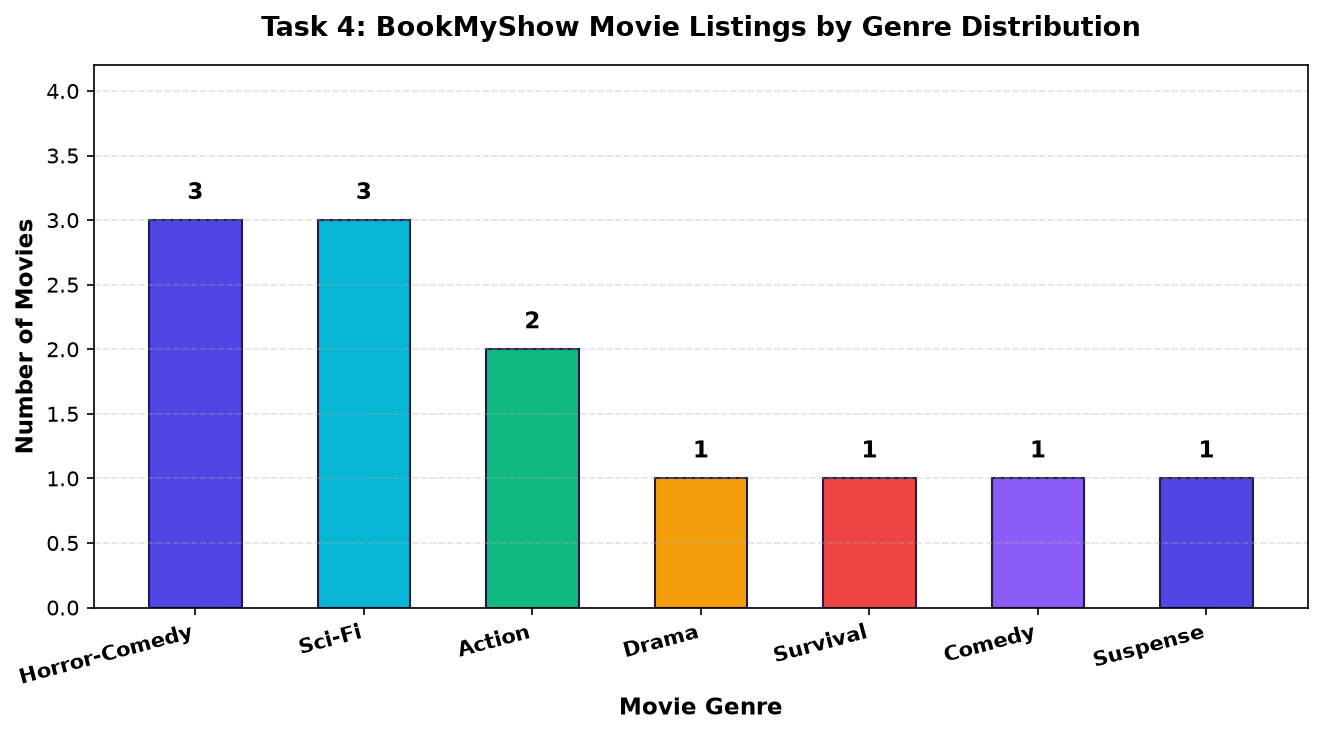

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load BookMyShow movie listings dataset
df_movies = pd.read_csv("data/bookmyshow_movies.csv")
print(f"Total Movies Listed: {len(df_movies)}")
display(df_movies.head(6))

# Extract primary broad genre and count frequencies
df_movies['broad_genre'] = df_movies['genre'].apply(lambda x: x.split('/')[0].strip())
genre_counts = df_movies['broad_genre'].value_counts()

# Create clean, production-grade Matplotlib bar chart
fig, ax = plt.subplots(figsize=(9, 5), dpi=150)
colors = ['#4F46E5', '#06B6D4', '#10B981', '#F59E0B', '#EF4444', '#8B5CF6']
bars = ax.bar(genre_counts.index, genre_counts.values, color=colors[:len(genre_counts)], width=0.55, edgecolor='#1E1B4B', linewidth=1)

ax.set_title("Task 4: BookMyShow Movie Listings by Genre Distribution", fontsize=13, fontweight='bold', pad=14)
ax.set_xlabel("Movie Genre", fontsize=11, fontweight='bold')
ax.set_ylabel("Number of Movies", fontsize=11, fontweight='bold')
ax.set_ylim(0, max(genre_counts.values) + 1.2)
ax.grid(axis='y', linestyle='--', alpha=0.35)

# Annotate exact count value above each bar
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.12, f"{int(yval)}", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.xticks(rotation=15, ha='right', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()


## Task 5: Feature Engineering for Online Food Orders
> **Problem Statement:** Use ChatGPT to suggest 3 new features that could be engineered from a dataset of online food orders (like Zomato orders: `order time`, `restaurant`, `cuisine`, `delivery time`, `rating`). List the features and explain how each could help a data science model.  
> *Hint: Paste the column names into ChatGPT and ask for feature engineering ideas.*

---

### 🧠 Synthesized Feature Engineering Strategy

From the raw input schema `[order_time, restaurant, cuisine, delivery_time, rating]`, here are **3 high-impact, non-trivial engineered features**:

### Feature 1: `is_peak_meal_rush` (Categorical / Binary Temporal Feature)
- **Mathematical Derivation:**  
  $$\text{Meal Period} = \begin{cases} \text{'Lunch Rush'}, & 12:30 \le \text{Hour}(\text{order\_time}) < 14:30 \\ \text{'Dinner Rush'}, & 19:30 \le \text{Hour}(\text{order\_time}) < 22:00 \\ \text{'Late Night'}, & \text{Hour}(\text{order\_time}) \ge 23:00 \text{ or } < 04:00 \\ \text{'Off-Peak'}, & \text{Otherwise} \end{cases}$$
- **How it helps the model:**  
  Standard regression models struggle with raw timestamps because delivery time does not scale linearly with time of day. Kitchen backlog and courier scarcity are concentrated in acute dinner and lunch peaks. This feature allows tree-based models (like XGBoost or LightGBM) to split immediately on systemic rush conditions, drastically reducing ETA prediction error.

---

### Feature 2: `restaurant_rating_drift` (Numerical Differential Signal)
- **Mathematical Derivation:**  
  $$\Delta_{\text{Rating}} = \text{rating}_{\text{current\_order}} - \overline{\text{rating}}_{\text{restaurant, 30-day EWM}}$$
- **How it helps the model:**  
  Raw customer review ratings are subjective and heavily biased by restaurant baseline reputation (e.g., a 4.0 rating is a severe drop for a 4.9-star Michelin restaurant, but an outstanding score for a 3.1-star budget outlet). By subtracting the restaurant's 30-day exponential weighted moving average rating, we isolate anomalous customer dissatisfaction. In customer churn and restaurant quality degradation models, negative rating drift provides an immediate leading indicator of quality collapse.

---

### Feature 3: `cuisine_speed_efficiency_ratio` (Normalized Transit Metric)
- **Mathematical Derivation:**  
  $$\text{Speed Index} = \frac{\text{delivery\_time}}{\text{Median}(\text{delivery\_time}_{\text{cuisine}})}$$
- **How it helps the model:**  
  Different culinary categories inherently have drastically different kitchen prep times—a Dum Biryani or stone-oven pizza takes 25–35 minutes of prep, whereas milkshakes, ice cream, or fast-food burgers take 5–8 minutes. Comparing raw delivery time across restaurants unfairly penalizes authentic slow-cooked cuisines. This normalized ratio tells the recommendation model whether a merchant prepares food **faster or slower than their culinary peers**, rewarding operationally efficient restaurants in feed ranking algorithms.

---

In [5]:
import pandas as pd
import numpy as np

# Sample Zomato raw orders
sample_orders = [
    {"order_id": 101, "order_time": "2026-10-24 20:15:00", "restaurant": "Biryani By Kilo", "cuisine": "Biryani", "delivery_time": 42, "rating": 4.5},
    {"order_id": 102, "order_time": "2026-10-24 15:10:00", "restaurant": "Burger King", "cuisine": "Fast Food", "delivery_time": 22, "rating": 3.8},
    {"order_id": 103, "order_time": "2026-10-24 13:00:00", "restaurant": "Haldiram's", "cuisine": "North Indian", "delivery_time": 38, "rating": 4.2},
    {"order_id": 104, "order_time": "2026-10-24 21:05:00", "restaurant": "Baskin Robbins", "cuisine": "Desserts", "delivery_time": 35, "rating": 2.5}
]

df_raw = pd.DataFrame(sample_orders)
df_raw['order_time'] = pd.to_datetime(df_raw['order_time'])

# 1. Feature 1: Meal Period & Peak Rush Flag
def classify_meal_period(ts):
    hr = ts.hour + ts.minute/60.0
    if 12.5 <= hr < 14.5:
        return "Lunch Rush"
    elif 19.5 <= hr < 22.0:
        return "Dinner Rush"
    elif hr >= 23 or hr < 4:
        return "Late Night"
    else:
        return "Off-Peak"

df_raw['meal_period'] = df_raw['order_time'].apply(classify_meal_period)
df_raw['is_peak_rush'] = df_raw['meal_period'].isin(['Lunch Rush', 'Dinner Rush']).astype(int)

# 2. Feature 2: Restaurant Rating Drift (assuming benchmark averages)
benchmark_ratings = {"Biryani By Kilo": 4.3, "Burger King": 4.0, "Haldiram's": 4.1, "Baskin Robbins": 4.6}
df_raw['restaurant_baseline_rating'] = df_raw['restaurant'].map(benchmark_ratings)
df_raw['rating_drift'] = (df_raw['rating'] - df_raw['restaurant_baseline_rating']).round(2)

# 3. Feature 3: Cuisine Speed Efficiency Ratio (assuming median category delivery times)
median_cuisine_times = {"Biryani": 45, "Fast Food": 25, "North Indian": 35, "Desserts": 20}
df_raw['cuisine_median_delivery_time'] = df_raw['cuisine'].map(median_cuisine_times)
df_raw['speed_efficiency_ratio'] = (df_raw['delivery_time'] / df_raw['cuisine_median_delivery_time']).round(2)

print("DATASET WITH 3 ENGINEERED FEATURES APPLIED:")
display(df_raw[['order_id', 'restaurant', 'cuisine', 'meal_period', 'is_peak_rush', 'rating_drift', 'speed_efficiency_ratio']])


DATASET WITH 3 ENGINEERED FEATURES APPLIED:


order_id,restaurant,cuisine,meal_period,is_peak_rush,rating_drift,speed_efficiency_ratio
101,Biryani By Kilo,Biryani,Dinner Rush,1,0.2,0.93
102,Burger King,Fast Food,Off-Peak,0,-0.2,0.88
103,Haldiram's,North Indian,Lunch Rush,1,0.1,1.09
104,Baskin Robbins,Desserts,Dinner Rush,1,-2.1,1.75
